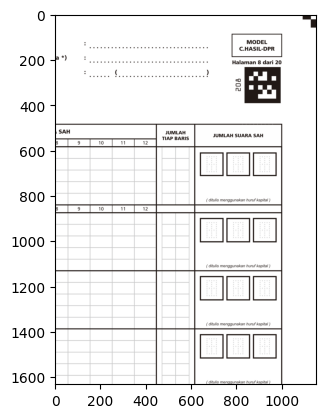

In [54]:
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import imutils

total_image = cv2.imread("features/topright.png")
def cv2_imshow(cv2image):
    plt.imshow(cv2.cvtColor(cv2image, cv2.COLOR_BGR2RGB))
    plt.show()
    
cv2_imshow(total_image)

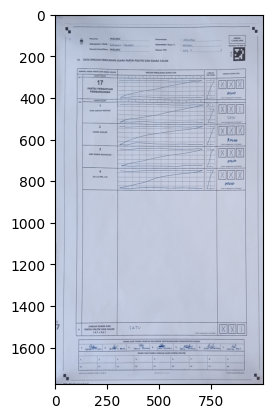

In [55]:
form_1_image = cv2.imread("forms/1.jpg")
cv2_imshow(form_1_image)


In [56]:
def filter_matches_with_amount(kp1, kp2, matches, ratio=0.75):
    mkp1, mkp2 = [], []
    total = 0
    for m in matches:
        if len(m) == 2 and m[0].distance < m[1].distance * ratio:
            m = m[0]
            total += 1
            mkp1.append(kp1[m.queryIdx])
            mkp2.append(kp2[m.trainIdx])
    kp_pairs = zip(mkp1, mkp2)
    return total, kp_pairs

def match(file_name: str):
    brisk = cv2.BRISK_create()
    form_image = cv2.imread(file_name)
    ref_kp, ref_descriptors = brisk.detectAndCompute(total_image, None)
    form_kp, form_descriptors = brisk.detectAndCompute(cv2.resize(form_image, None, fx=1.0, fy=1.0), None)
    
    # create BFMatcher object
    BFMatcher = cv2.BFMatcher(normType = cv2.NORM_HAMMING, crossCheck = True)
    # 
    brisk = cv2.BRISK_create()
    im_kp, im_descriptors = brisk.detectAndCompute(cv2.resize(form_image, None, fx=1.0, fy=1.0), None)
    # logging.info("BRISK image %s", (datetime.now() - lap).total_seconds())
    # lap = datetime.now()
    # 
    bf = cv2.BFMatcher(cv2.NORM_L2)
    raw_matches = bf.knnMatch(np.float32(im_descriptors), trainDescriptors=np.float32(ref_descriptors), k=2)
    # logging.info("knn matched %s", (datetime.now() - lap).total_seconds())
    # lap = datetime.now()
    # 
    amount, matches = filter_matches_with_amount(im_kp, ref_kp, raw_matches)
    mkp1, mkp2 = zip(*matches)
    # logging.warning("matches %s", matches.__sizeof__())
    # 
    # 
    # # show_match(im_kp, image, raw_matches, ref_kp, reference_form_path)
    # 
    p1 = np.float32([kp.pt for kp in mkp1])
    p2 = np.float32([kp.pt for kp in mkp2])
    # 
    homography_transform, mask = cv2.findHomography(p1, p2, cv2.RANSAC, 5.0)
    # 
    # logging.info("RANSAC  %s", (datetime.now() - lap).total_seconds())
    # lap = datetime.now()
    # 
    # homography, transform = check_homography(homography_transform)
    # 
    # # good_enough_match = check_match(homography, transform)
    # good_enough_match = True
    # 
    print(form_image.shape)
    h = form_image.shape[0]
    w = form_image.shape[1]
    image_transformed = cv2.warpPerspective(form_image, homography_transform, (w, h))
    cv2_imshow(image_transformed)
    
    
    # Matching descriptor vectors using Brute Force Matcher
    matches = BFMatcher.match(queryDescriptors = ref_descriptors,
                              trainDescriptors = form_descriptors)
    
    # Sort them in the order of their distance
    matches = sorted(matches, key = lambda x: x.distance)
    
    # Draw first 15 matches
    output = cv2.drawMatches(img1 = total_image,
                            keypoints1 = ref_kp,
                            img2 = form_image,
                            keypoints2 = form_kp,
                            matches1to2 = matches[:15],
                            outImg = None,
                            flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    
    cv2_imshow(output)

(1777, 1000, 3)


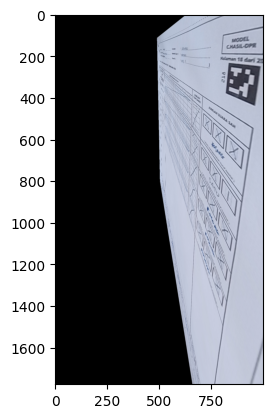

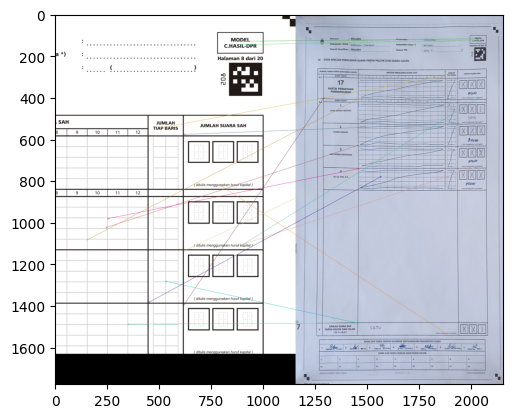

In [57]:
match("forms/1.jpg")
# match("forms/2.jpg")
# match("forms/3.jpg")
# match("forms/4.jpg")
# match("forms/5.jpg")
# match("forms/6.jpg")